In [1]:
!pip install xgboost --quiet

In [2]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from xgboost import XGBClassifier  # Import XGBoost

from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.metrics import make_scorer, f1_score
import time
import joblib


In [3]:
#drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/feature_stats_training.csv"
#features_path = "/content/drive/MyDrive/feature_stats_training.csv"

In [5]:
df = pd.read_csv(data_path)

In [6]:
df_features = df.drop(columns = ['label', 'system:index']).copy()
dfclass = df[['label', '.geo']].copy()

dfclass.rename(columns = {'label':'class'}, inplace = True)
dfclass.rename(columns = {'.geo':'location'}, inplace = True)
df_features.rename(columns = {'.geo':'location'}, inplace = True)
cols = df_features.columns.tolist()

In [8]:
# Try using Logistic Regression to create a baseline
# Separate features and target
X = df_features.drop(columns=['location'])
y = dfclass['class']

# Convert target to binary: 1 for the desired class, 0 for others
# Assuming '1' in the 'class' column is the desired class
y_binary = (y == 1).astype(int)

# Split data into training and testing sets
X_train, X_test, y_train_binary, y_test_binary = train_test_split(X, y_binary, test_size=0.25, random_state=42)

# Build a logistic regression classifier
classifier = LogisticRegression(random_state=42, max_iter=5000, penalty="l1", solver='liblinear', C=0.5) # max_iter for convergence

# Train the classifier
classifier.fit(X_train, y_train_binary)

# Make predictions on the test set
y_pred_binary = classifier.predict(X_test)

# Evaluate the classifier
print(classification_report(y_test_binary, y_pred_binary))

              precision    recall  f1-score   support

           0       0.94      0.95      0.95      6257
           1       0.95      0.94      0.95      6243

    accuracy                           0.95     12500
   macro avg       0.95      0.95      0.95     12500
weighted avg       0.95      0.95      0.95     12500



In [9]:
# Access the coefficients of the logistic regression model
coefficients = classifier.coef_[0]

# Get the feature names
feature_names = X_train.columns

# Create a pandas series to easily view coefficients with their corresponding feature names
feature_importance = pd.Series(coefficients, index=feature_names)

# Sort the features by their absolute coefficient values (importance)
# The argsort() method returns the indices that would sort the array,
# so we are getting the original column indices sorted by their absolute coefficient values
sorted_feature_importance = feature_importance.abs().argsort()
print("Feature Importance (Absolute Coefficients):")
# Access the feature names in the sorted order
print(feature_names[sorted_feature_importance])

# You can also print the actual coefficients to see the direction of the relationship
print("\nFeature Coefficients:")
print(feature_importance.sort_values(key=abs, ascending=False))

Feature Importance (Absolute Coefficients):
Index(['GNDWI_stdDev', 'MSR_median', 'GNDWI_mean', 'NDRE_min', 'RENDVI_min',
       'RENDVI_stdDev', 'NDRE_stdDev', 'GLCM_var', 'GNDWI_skew',
       'GNDWI_kurtosis', 'RENDVI_kurtosis', 'MSR_kurtosis', 'NDRE_kurtosis',
       'MSR_max', 'GNDVI_kurtosis', 'BSI_kurtosis', 'NDRE_skew', 'MSR_skew',
       'RENDVI_skew', 'GNDVI_skew', 'BSI_skew', 'NDRE_max', 'RENDVI_median',
       'GLCM_corr', 'GNDWI_median', 'MSR_stdDev', 'BSI_median', 'NDRE_median',
       'GNDVI_min', 'GNDWI_max', 'MSR_min', 'GNDWI_min', 'BSI_max',
       'NDRE_mean', 'GNDVI_max', 'BSI_mean', 'GNDVI_median', 'RENDVI_mean',
       'MSR_mean', 'BSI_min', 'RENDVI_max', 'GNDVI_stdDev', 'BSI_stdDev',
       'GNDVI_mean'],
      dtype='object')

Feature Coefficients:
GNDVI_mean         30.059232
BSI_stdDev         21.212018
GNDVI_stdDev      -18.526723
RENDVI_max         15.744319
BSI_min           -13.429394
MSR_mean          -12.606770
RENDVI_mean       -12.033535
GNDVI_median    

In [22]:
# Access the feature names in the sorted order and filter based on absolute coefficient value
important_features = feature_importance[feature_importance.abs() > 10].sort_values(key=abs, ascending=False)

print("\nFeatures with Absolute Coefficient > 10:")
important_features


Features with Absolute Coefficient > 10:


,0
GNDVI_mean,30.059232
BSI_stdDev,21.212018
GNDVI_stdDev,-18.526723
RENDVI_max,15.744319
BSI_min,-13.429394
MSR_mean,-12.606770
RENDVI_mean,-12.033535
GNDVI_median,10.625491


In [23]:
# Try using Logistic Regression to create a baseline
# Separate features and target
X = df_features[important_features.index]
y = dfclass['class']

# Convert target to binary: 1 for the desired class, 0 for others
# Assuming '1' in the 'class' column is the desired class
y_binary = (y == 1).astype(int)

# Split data into training and testing sets
X_train, X_test, y_train_binary, y_test_binary = train_test_split(X, y_binary, test_size=0.25, random_state=42)

# Build a logistic regression classifier
classifier = LogisticRegression(random_state=42, max_iter=5000, penalty=None) # max_iter for convergence

# Train the classifier
classifier.fit(X_train, y_train_binary)

# Make predictions on the test set
y_pred_binary = classifier.predict(X_test)

# Evaluate the classifier
print(classification_report(y_test_binary, y_pred_binary))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93      6257
           1       0.93      0.93      0.93      6243

    accuracy                           0.93     12500
   macro avg       0.93      0.93      0.93     12500
weighted avg       0.93      0.93      0.93     12500



Confusion Matrix:
[[0.93047786 0.06952214]
 [0.0691975  0.9308025 ]]


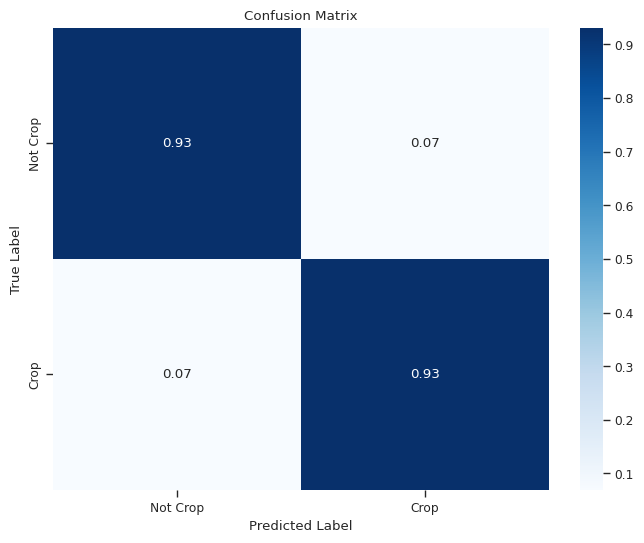

In [24]:
sns.set(style="whitegrid")
sns.set_context("paper")
sns.set_palette("colorblind")
sns.set_style("ticks")

# Print the confusion matrix
cm = confusion_matrix(y_test_binary, y_pred_binary, normalize='true')
print("Confusion Matrix:")
print(cm)

# Optionally visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=['Not Crop', 'Crop'], yticklabels=['Not Crop', 'Crop'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [25]:
# Build an XGBoost classifier
# You can tune the hyperparameters of XGBoost for better performance
xgb_classifier = XGBClassifier(random_state=42, eval_metric='logloss')

# Train the classifier
xgb_classifier.fit(X_train, y_train_binary)

# Make predictions on the test set
y_pred_binary = xgb_classifier.predict(X_test)

# Evaluate the classifier
print(classification_report(y_test_binary, y_pred_binary))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      6257
           1       0.94      0.94      0.94      6243

    accuracy                           0.94     12500
   macro avg       0.94      0.94      0.94     12500
weighted avg       0.94      0.94      0.94     12500



In [13]:
print("\nDefault parameters of the XGBoost classifier:")
print(xgb_classifier.get_params())


Default parameters of the XGBoost classifier:
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'logloss', 'feature_types': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [26]:
# Get feature importance from the trained XGBoost model
feature_importance_xgb = xgb_classifier.feature_importances_

# Create a pandas Series for easy viewing with feature names
feature_importance_xgb_series = pd.Series(feature_importance_xgb, index=X_train.columns)

# Sort features by importance in descending order
sorted_feature_importance_xgb = feature_importance_xgb_series.sort_values(ascending=False)

print("\nXGBoost Feature Importance (Sorted):")
sorted_feature_importance_xgb


XGBoost Feature Importance (Sorted):


,0
BSI_stdDev,0.561152
MSR_mean,0.181694
RENDVI_mean,0.063634
BSI_min,0.050551
GNDVI_median,0.049933
GNDVI_stdDev,0.042215
GNDVI_mean,0.029838
RENDVI_max,0.020982


In [34]:
print('Selected Features: ', sorted_feature_importance_xgb.index)

Selected Features:  Index(['BSI_stdDev', 'MSR_mean', 'RENDVI_mean', 'BSI_min', 'GNDVI_median',
       'GNDVI_stdDev', 'GNDVI_mean', 'RENDVI_max'],
      dtype='object')


In [20]:
# Calculate the total importance for percentage calculation
total_importance = sorted_feature_importance_xgb.sum()

# Calculate the relative percentage importance
relative_percentage_importance = (sorted_feature_importance_xgb / total_importance) * 100

print("\nXGBoost Feature Importance (Relative Percentage):")
relative_percentage_importance


XGBoost Feature Importance (Relative Percentage):


,0
BSI_stdDev,41.534664
BSI_max,10.183110
MSR_mean,6.835487
MSR_min,3.249447
BSI_min,2.853441
GNDVI_max,1.840839
GLCM_var,1.786643
GNDVI_median,1.754325
RENDVI_mean,1.608367
NDRE_min,1.583706


In [28]:
y.head()

,class
0,1
1,1
2,1
3,1
4,1


In [ ]:
# Based on XGBoost, dropping the following features
#dropped_cols = ['GLCM_contrast', 'SAVI', 'MSR', 'GLCM_corr', 'RENDVI', 'GLCM_asm']

In [29]:
print("Setting up Grid Search for XGBoost hyperparameter tuning...")

#X.drop(columns=dropped_cols, inplace=True)

start_time = time.time()
# Define the model
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')

# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'subsample': [0.7, 0.8, 0.9]
}

# Define the cross-validation strategy
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Define the scorer (using F1-score as an example)
scorer = make_scorer(f1_score)

# Perform Grid Search with cross-validation
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, scoring=scorer, cv=cv, n_jobs=-1)
end_time = time.time()
print(f"Grid Search setup complete in {end_time - start_time:.2f} seconds.")

print("Starting Grid Search ...")
start_time = time.time()
grid_search.fit(X, y_binary)
end_time = time.time()
print(f"Grid Search completed in {end_time - start_time:.2f} seconds.")

print("\nBest parameters found by Grid Search:")
print(grid_search.best_params_)
print("\nBest cross-validation F1-score from Grid Search:")
print(grid_search.best_score_)



Setting up Grid Search for XGBoost hyperparameter tuning...
Grid Search setup complete in 0.00 seconds.
Starting Grid Search ...
Grid Search completed in 1034.78 seconds.

Best parameters found by Grid Search:
{'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}

Best cross-validation F1-score from Grid Search:
0.9425305783723144


In [30]:
# Split data into training and testing sets
X_train, X_test, y_train_binary, y_test_binary = train_test_split(X, y_binary, test_size=0.25, random_state=42)

print("Evaluating the best model on the test set...")
start_time = time.time()
# Evaluate the best model on the test set (optional, as cross-validation already provides an estimate)
best_xgb_model = grid_search.best_estimator_
y_pred_binary_optimized = best_xgb_model.predict(X_test)
print("\nClassification report for the best model on the test set:")
print(classification_report(y_test_binary, y_pred_binary_optimized))
end_time = time.time()
print(f"Evaluation of best model on test set complete in {end_time - start_time:.2f} seconds.")


print("Performing cross-validation with the best parameters...")
start_time = time.time()
# Optional: Perform cross-validation with the best parameters
print("\nCross-validation scores with the best parameters:")
cv_scores_optimized = cross_val_score(best_xgb_model, X, y_binary, cv=cv, scoring=scorer)
print(cv_scores_optimized)
print("Mean cross-validation F1-score with best parameters:", cv_scores_optimized.mean())
end_time = time.time()
print(f"Cross-validation with best parameters complete in {end_time - start_time:.2f} seconds.")


Evaluating the best model on the test set...

Classification report for the best model on the test set:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      6257
           1       0.97      0.97      0.97      6243

    accuracy                           0.97     12500
   macro avg       0.97      0.97      0.97     12500
weighted avg       0.97      0.97      0.97     12500

Evaluation of best model on test set complete in 0.08 seconds.
Performing cross-validation with the best parameters...

Cross-validation scores with the best parameters:
[0.94302164 0.94448866 0.94210847 0.94107072 0.94196341]
Mean cross-validation F1-score with best parameters: 0.9425305783723144
Cross-validation with best parameters complete in 5.43 seconds.



Feature Importances from the Best XGBoost Model:
        Feature  Importance
1    BSI_stdDev    0.384837
6   RENDVI_mean    0.149741
4       BSI_min    0.137694
5      MSR_mean    0.118559
7  GNDVI_median    0.073135
2  GNDVI_stdDev    0.050739
3    RENDVI_max    0.048349
0    GNDVI_mean    0.036947


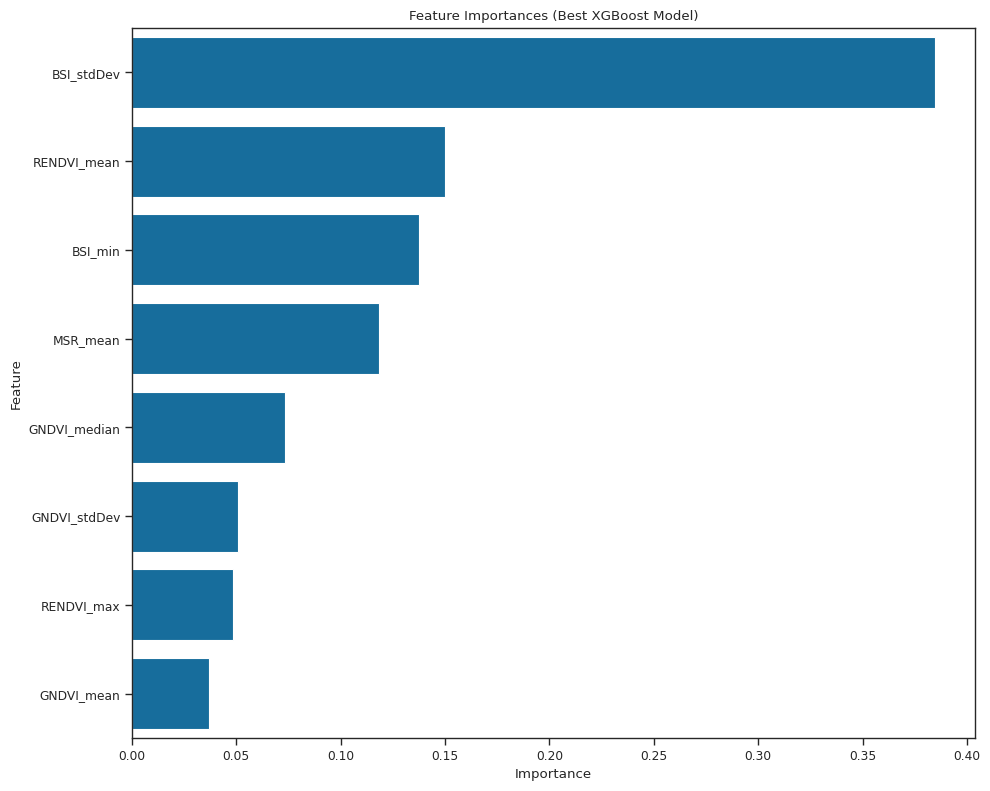

In [31]:
# Print feature importances from the best model
print("\nFeature Importances from the Best XGBoost Model:")
feature_importances = best_xgb_model.feature_importances_
features = X.columns
importance_df = pd.DataFrame({'Feature': features, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print(importance_df)

# Optionally visualize feature importances
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importances (Best XGBoost Model)')
plt.tight_layout()
plt.show()

In [ ]:
# ASM: Angular Singular Moment
# RENDVI: Red-Edge NDVI
X = df_features.drop(columns=['GLCM_contrast', 'SAVI', 'MSR', 'GLCM_corr', 'RENDVI', 'GLCM_asm', 'location'])
# Split data into training and testing sets
X_train, X_test, y_train_binary, y_test_binary = train_test_split(X, y_binary, test_size=0.25, random_state=42)
xgb_model_selected = XGBClassifier(random_state=42, eval_metric='logloss', n_estimators=grid_search.best_params_['n_estimators'], max_depth=grid_search.best_params_['max_depth'], learning_rate=grid_search.best_params_['learning_rate'], colsample_bytree=grid_search.best_params_['colsample_bytree'], subsample=grid_search.best_params_['subsample'])
# Train the classifier
xgb_model_selected.fit(X_train, y_train_binary)

# Make predictions on the test set
y_pred_binary = xgb_model_selected.predict(X_test)

# Evaluate the classifier
print(classification_report(y_test_binary, y_pred_binary))

              precision    recall  f1-score   support

           0       0.74      0.66      0.70      6250
           1       0.69      0.77      0.73      6232

    accuracy                           0.71     12482
   macro avg       0.72      0.71      0.71     12482
weighted avg       0.72      0.71      0.71     12482



In [32]:
grid_search.best_params_

{'colsample_bytree': 0.7,
 'learning_rate': 0.1,
 'max_depth': 7,
 'n_estimators': 200,
 'subsample': 0.8}

In [33]:

# Save the model
filename = '/content/best_xgb_model.joblib'
joblib.dump(best_xgb_model, filename)
print(f"Model saved to {filename}")

# Load the model later for inference
loaded_model = joblib.load(filename)
print(f"Model loaded from {filename}")

# Example:
# new_predictions = loaded_model.predict(new_X_data)
# print(new_predictions)

Model saved to /content/best_xgb_model.joblib
Model loaded from /content/best_xgb_model.joblib


In [ ]:
# --- Bayesian Optimization (using bayes_opt) ---
!pip install bayesian-optimization

from bayes_opt import BayesianOptimization

# Define the parameter space for Bayesian Optimization
# The bounds of the parameters to be optimized
pbounds = {
    'n_estimators': (250, 500),
    'learning_rate': (0.06, 0.1, 0.13),
    'max_depth': (3, 7),
    'colsample_bytree': (0.7, 0.9),
    'subsample': (0.7, 0.9)
}

# Define the function to optimize (cross-validated F1-score)
def xgb_cross_val(n_estimators, learning_rate, max_depth, colsample_bytree, subsample):
    # XGBoost requires integer for n_estimators and max_depth
    n_estimators = int(n_estimators)
    max_depth = int(max_depth)

    model = XGBClassifier(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        colsample_bytree=colsample_bytree,
        subsample=subsample,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    cv_result = cross_val_score(model, X, y_binary, cv=cv, scoring=scorer)
    return cv_result.mean()

# Initialize Bayesian Optimization
optimizer = BayesianOptimization(
    f=xgb_cross_val,
    pbounds=pbounds,
    random_state=42,
)

# Run the optimization
print("\nStarting Bayesian Optimization...")
optimizer.maximize(
    init_points=5,  # Number of random exploration steps
    n_iter=10,      # Number of optimization steps
)

# Print the best parameters and the best score found by Bayesian Optimization
print("\nBest parameters found by Bayesian Optimization:")
print(optimizer.max['params'])
print("Best cross-validation F1-score found by Bayesian Optimization:")
print(optimizer.max['target'])

# Train a model with the best parameters found by Bayesian Optimization
best_bo_params = optimizer.max['params']
best_bo_params['n_estimators'] = int(best_bo_params['n_estimators'])
best_bo_params['max_depth'] = int(best_bo_params['max_depth'])

best_xgb_bo_model = XGBClassifier(
    **best_bo_params,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
best_xgb_bo_model.fit(X_train, y_train_binary)

# Evaluate the best BO model on the test set
y_pred_binary_bo_optimized = best_xgb_bo_model.predict(X_test)
print("\nClassification report for the best BO model on the test set:")
print(classification_report(y_test_binary, y_pred_binary_bo_optimized))